In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
url = "https://raw.githubusercontent.com/NidhiU-24/Student-Mental-Health-Assessment/main/students_mental_health_survey.csv"
df = pd.read_csv(url)
df.head()

,Age,Course,Gender,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,Male,3.56,3,3,2,Good,Moderate,Good,Moderate,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,Female,2.44,0,3,0,Average,Low,Average,Low,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,Female,3.74,4,0,3,Good,Low,Average,Moderate,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
3,19,Computer Science,Male,3.65,2,1,0,Average,Low,Average,Moderate,Single,NaN,Never,No,No,4,Moderate,20,Off-Campus
4,18,Business,Male,3.40,3,3,4,Good,Low,Average,High,Married,Never,Never,No,Yes,0,High,23,On-Campus


In [3]:
df.shape

(7022, 20)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7022 entries, 0 to 7021
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          7022 non-null   int64  
 1   Course                       7022 non-null   object 
 2   Gender                       7022 non-null   object 
 3   CGPA                         7010 non-null   float64
 4   Stress_Level                 7022 non-null   int64  
 5   Depression_Score             7022 non-null   int64  
 6   Anxiety_Score                7022 non-null   int64  
 7   Sleep_Quality                7022 non-null   object 
 8   Physical_Activity            7022 non-null   object 
 9   Diet_Quality                 7022 non-null   object 
 10  Social_Support               7022 non-null   object 
 11  Relationship_Status          7022 non-null   object 
 12  Substance_Use                7007 non-null   object 
 13  Counseling_Service

In [5]:
df.columns

Index(['Age', 'Course', 'Gender', 'CGPA', 'Stress_Level', 'Depression_Score',
       'Anxiety_Score', 'Sleep_Quality', 'Physical_Activity', 'Diet_Quality',
       'Social_Support', 'Relationship_Status', 'Substance_Use',
       'Counseling_Service_Use', 'Family_History', 'Chronic_Illness',
       'Financial_Stress', 'Extracurricular_Involvement',
       'Semester_Credit_Load', 'Residence_Type'],
      dtype='object')

In [6]:
df.describe()

,Age,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Financial_Stress,Semester_Credit_Load
count,7022.000000,7010.00000,7022.000000,7022.000000,7022.000000,7022.000000,7022.000000
mean,23.003418,3.49127,2.427941,2.254486,2.300484,2.453005,22.010538
std,3.853978,0.28742,1.638408,1.625193,1.624305,1.708995,4.358380
min,18.000000,2.44000,0.000000,0.000000,0.000000,0.000000,15.000000
25%,20.000000,3.29000,1.000000,1.000000,1.000000,1.000000,18.000000
50%,22.000000,3.50000,2.000000,2.000000,2.000000,2.000000,22.000000
75%,25.000000,3.70000,4.000000,3.000000,4.000000,4.000000,26.000000
max,35.000000,4.00000,5.000000,5.000000,5.000000,5.000000,29.000000


In [7]:
df.isnull().sum()

Age                             0
Course                          0
Gender                          0
CGPA                           12
Stress_Level                    0
Depression_Score                0
Anxiety_Score                   0
Sleep_Quality                   0
Physical_Activity               0
Diet_Quality                    0
Social_Support                  0
Relationship_Status             0
Substance_Use                  15
Counseling_Service_Use          0
Family_History                  0
Chronic_Illness                 0
Financial_Stress                0
Extracurricular_Involvement     0
Semester_Credit_Load            0
Residence_Type                  0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
Column = ['Age', 'Course', 'Gender', 'CGPA', 'Stress_Level', 'Depression_Score',
       'Anxiety_Score', 'Sleep_Quality', 'Physical_Activity', 'Diet_Quality',
       'Social_Support', 'Relationship_Status', 'Substance_Use',
       'Counseling_Service_Use', 'Family_History', 'Chronic_Illness',
       'Financial_Stress', 'Extracurricular_Involvement',
       'Semester_Credit_Load', 'Residence_Type']

for i in Column[1:]:
    print(df[i].value_counts(dropna=False))

Course
Medical             2105
Law                 1385
Engineering         1072
Computer Science    1028
Business             717
Others               715
Name: count, dtype: int64
Gender
Male      3547
Female    3475
Name: count, dtype: int64
CGPA
4.00    332
3.51    106
3.58    106
3.55    105
3.50    103
       ... 
2.58      1
2.66      1
2.61      1
2.44      1
2.67      1
Name: count, Length: 144, dtype: int64
Stress_Level
3    1405
2    1279
1    1233
0    1098
5    1015
4     992
Name: count, dtype: int64
Depression_Score
3    1388
1    1308
2    1304
0    1295
4     884
5     843
Name: count, dtype: int64
Anxiety_Score
3    1429
2    1297
1    1270
0    1243
4     912
5     871
Name: count, dtype: int64
Sleep_Quality
Good       3589
Average    2735
Poor        698
Name: count, dtype: int64
Physical_Activity
Moderate    3521
Low         2091
High        1410
Name: count, dtype: int64
Diet_Quality
Average    4268
Good       1385
Poor       1369
Name: count, dtype: int64
Social

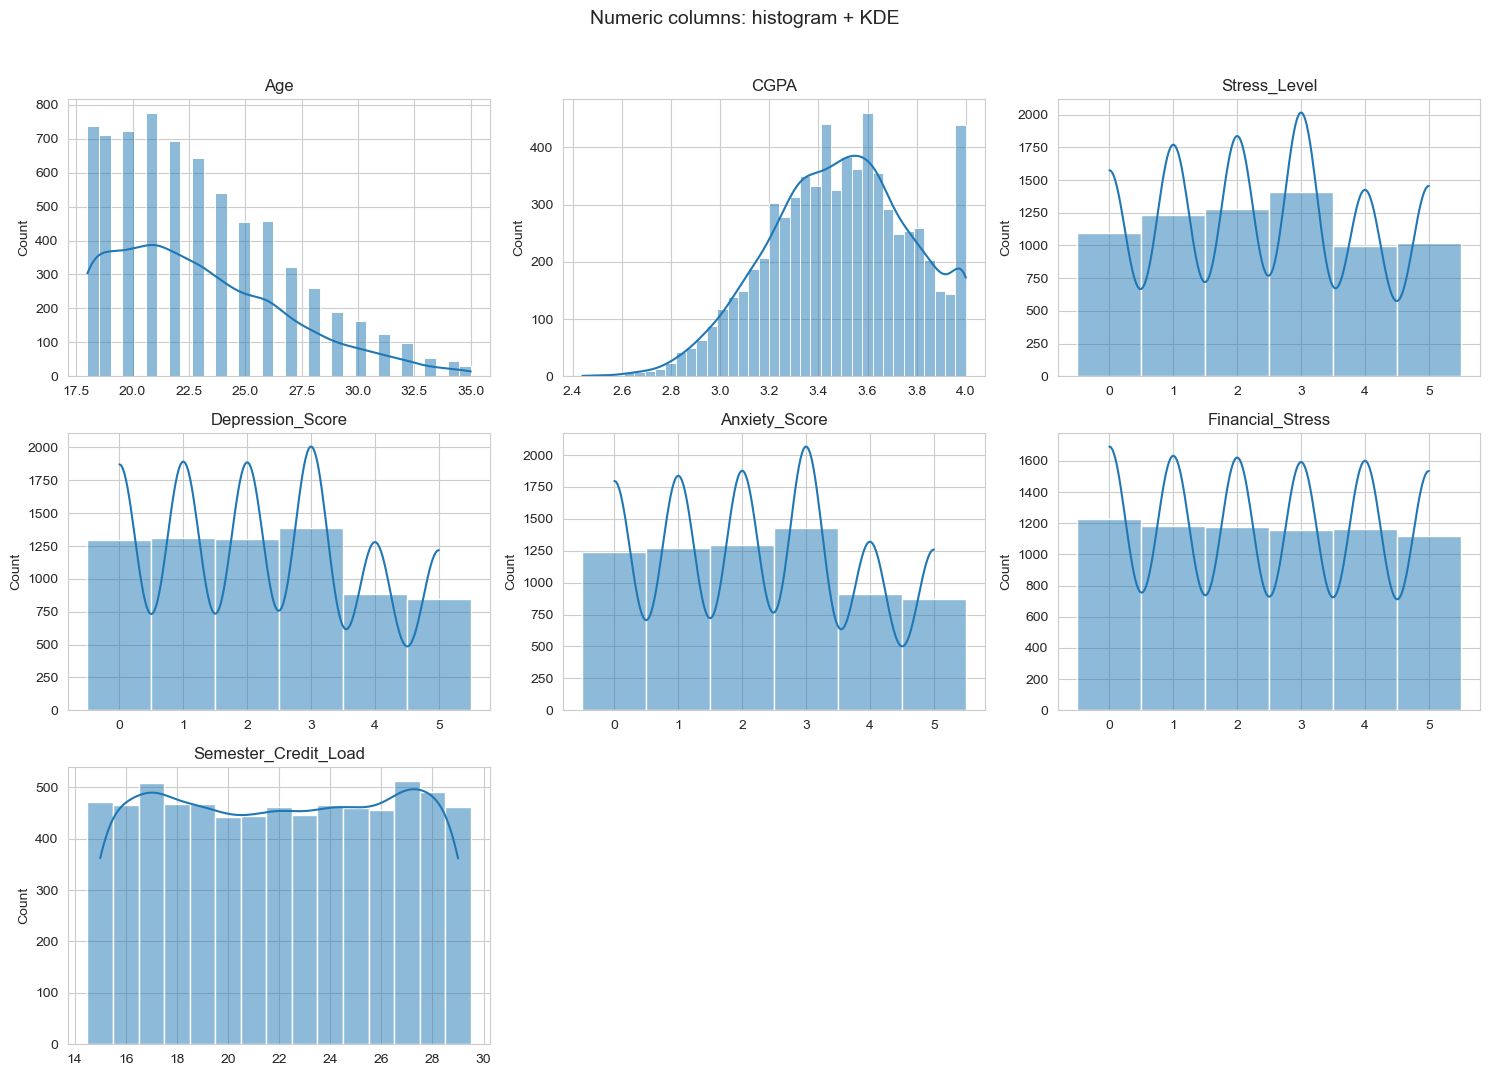

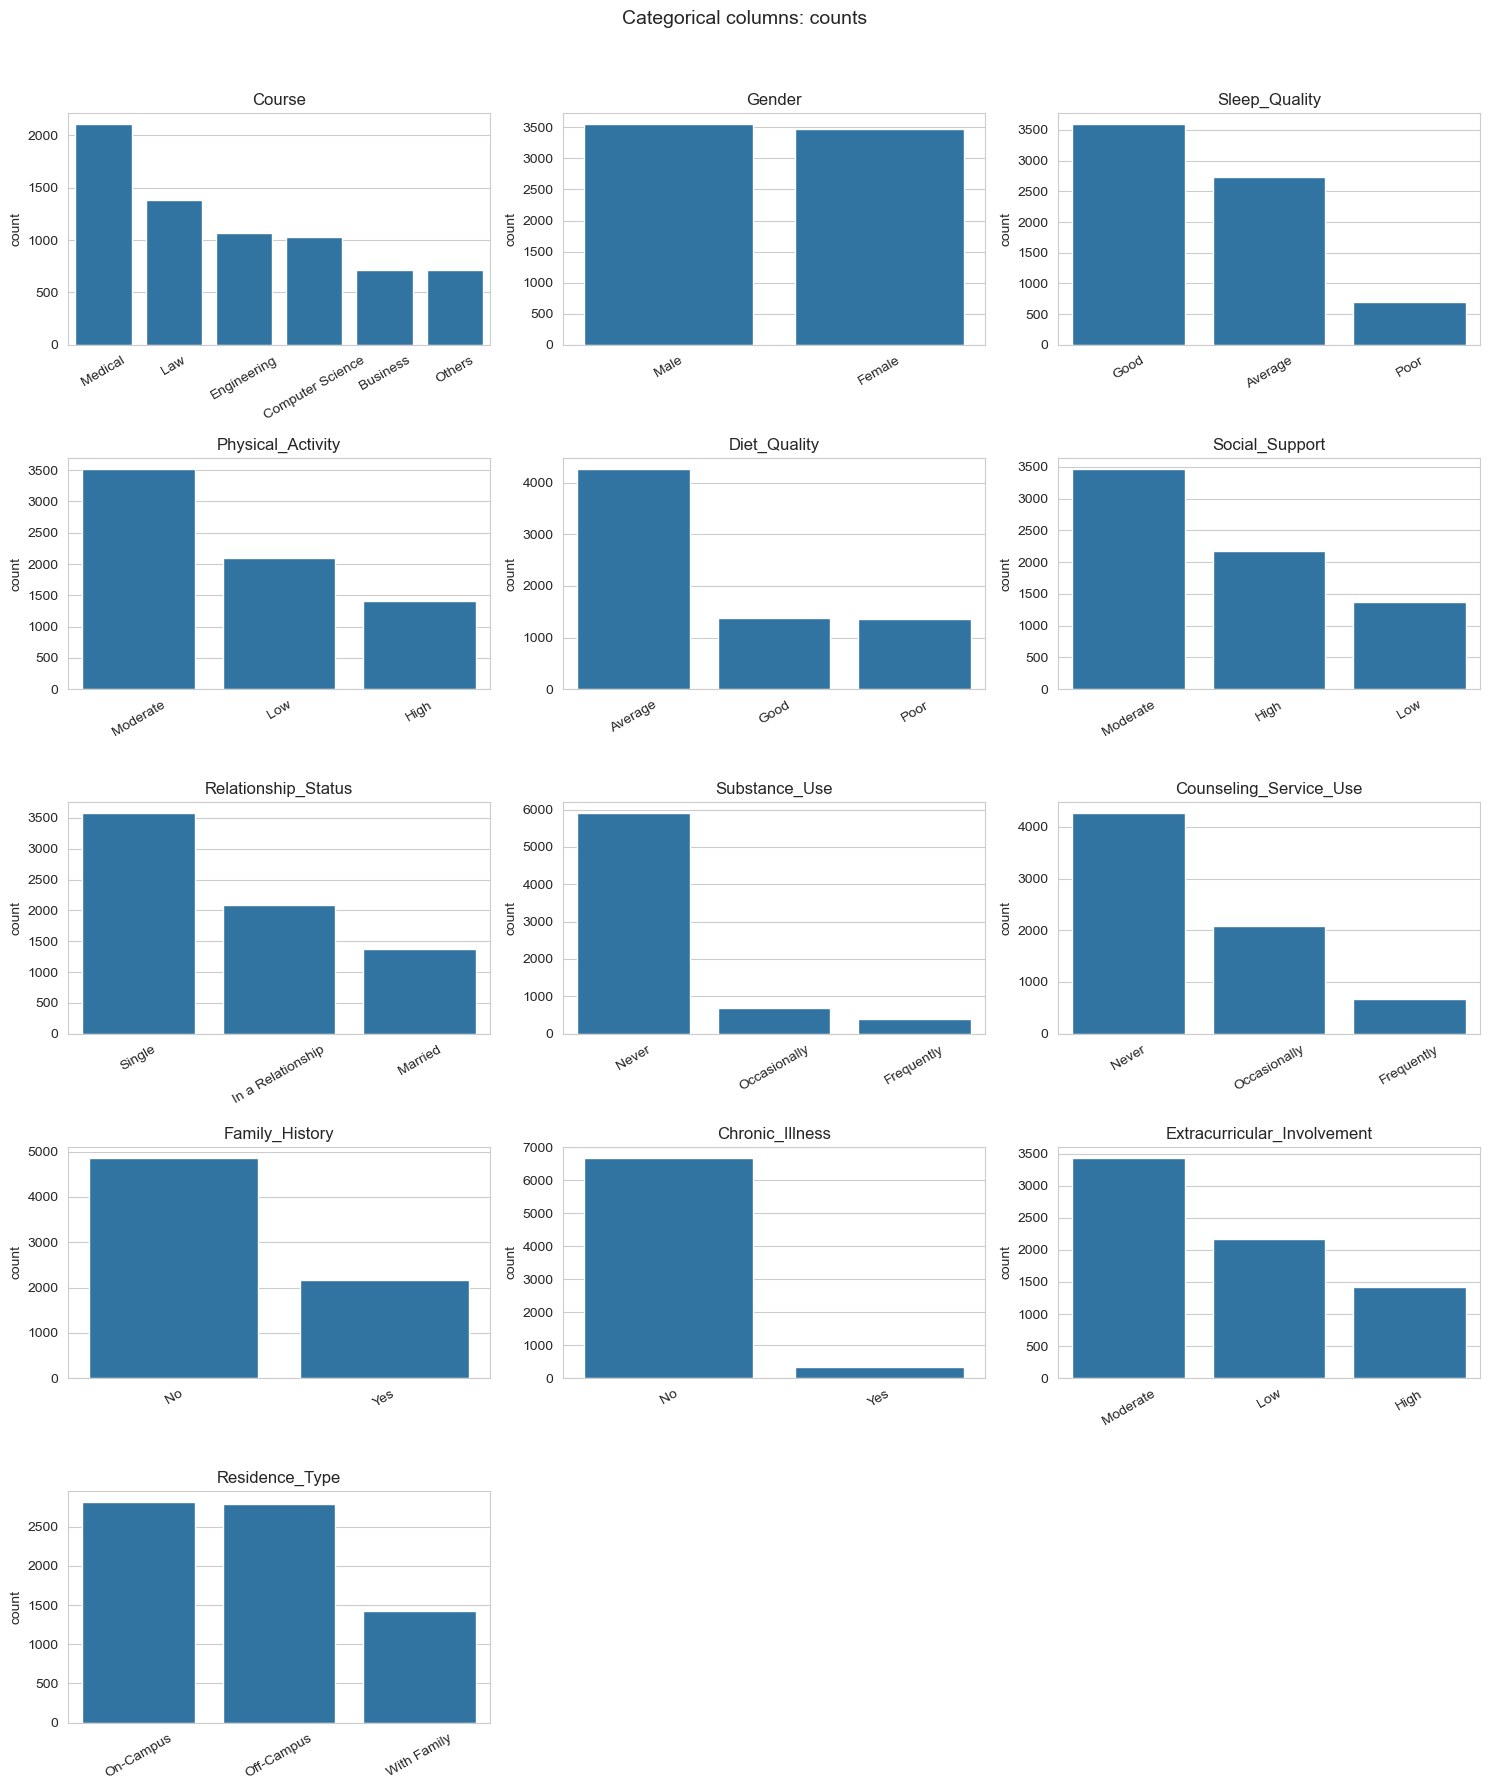

In [10]:
sns.set_style("whitegrid")

num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

def plot_grid(cols, plot_func, ncols=3, figsize_per=(5, 3.5), title=None):
    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0] * ncols, figsize_per[1] * nrows))
    axes = axes.flatten()
    for ax, col in zip(axes, cols):
        plot_func(col, ax)
        ax.set_title(col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)   # hide empty subplots
    if title:
        fig.suptitle(title, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# 1. Numeric columns: histogram + KDE
def num_plot(col, ax):
    # discrete=True gives clean bars for integer scales like 0-5
    discrete = df[col].nunique() <= 15
    sns.histplot(df[col].dropna(), kde=True, discrete=discrete, ax=ax)
    ax.set_xlabel("")

plot_grid(num_cols, num_plot, title="Numeric columns: histogram + KDE")

# 2. Categorical columns: count plots
def cat_plot(col, ax):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plot_grid(cat_cols, cat_plot, title="Categorical columns: counts")